# 03 - Phase matching and gain

This notebook uses `twpasolver.TWPAnalysis` to compute the phase matching and the gain of a 3WM KI-TWPA, solving the coupled mode equations (CMEs) for pump, signal and idler.

## Overview

`TWPAnalysis` holds a `TWPA` model and a frequency grid and provides:

* `linear`: the linear response of the device, computed on demand and recomputed when the model or the grid change;
* `phase_matching()`, which returns a `PhaseMatchingResult`;
* `gain()`, which returns a `GainResult` with the bandwidth (`r.bandwidth()`), a plot (`r.plot()`) and HDF5 saving (`r.save(path)`, read back with `GainResult.load(path)`).

The methods return their results and store nothing, so a parameter sweep is a plain loop.

## Setup

`TWPAnalysis` takes:

* `twpa`: a `TWPA` or the path of its JSON file;
* `freqs`: the frequency grid, a list of values or a tuple `(start, stop, step)` passed to `numpy.arange`, in `unit` (GHz by default).

The grid is used to unwrap the phase of the line, so it should be dense and start well below the first stopband.

## Units

* Frequencies passed to and returned by `TWPAnalysis` are in `unit`; the models (notebooks 01 and 02) work in Hz.
* Currents (`Is0`, `Ip0` and the mode currents of the results) are peak amplitudes in A; `dBm_to_I` converts a power in dBm.
* Positions along the line are in unit cells, wavenumbers in rad per unit cell and gains in dB.

/home/cns20/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "
/home/cns20/.local/lib/python3.10/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


{'Z0_ref': 50.0,
 'N': 1200,
 'cells': [{'Z0_ref': 50.0,
   'N': 15,
   'name': 'LCLfBaseCell',
   'L': 5.55e-11,
   'C': 2.19e-14,
   'Lf': 1.2e-10,
   'delta': 0.0002,
   'qp_loss': 0.0,
   'nl_scale': 1.0,
   'centered': True},
  {'Z0_ref': 50.0,
   'N': 4,
   'name': 'LCLfBaseCell',
   'L': 5.52e-11,
   'C': 8.3e-15,
   'Lf': 3.9e-11,
   'delta': 0.0002,
   'qp_loss': 0.0,
   'nl_scale': 1.0,
   'centered': True},
  {'Z0_ref': 50.0,
   'N': 15,
   'name': 'LCLfBaseCell',
   'L': 5.55e-11,
   'C': 2.19e-14,
   'Lf': 1.2e-10,
   'delta': 0.0002,
   'qp_loss': 0.0,
   'nl_scale': 1.0,
   'centered': True}],
 'name': 'TWPA',
 'Istar': 0.002,
 'Idc': 0.0002,
 'Ip0': 0.0001,
 'N_tot': 40800,
 'epsilon': 99.00990099009904,
 'xi': 247524.75247524757,
 'chi': 0.00030940594059405946,
 'alpha': 1.01,
 'Iratio': 0.1}

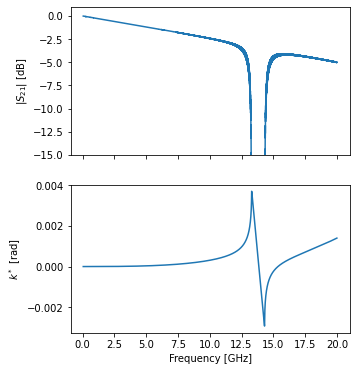

In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np

from twpasolver import TWPAnalysis
from twpasolver.logger import log
from twpasolver.mathutils import dBm_to_I

log.setLevel(logging.WARNING)

plt.rcParams["font.size"] = 13.5
plt.rcParams["axes.axisbelow"] = True

twpa_file = "imskit_v3_holotype.json"  # Representative circuit model from https://doi.org/10.1103/yg71-j2dn
a = TWPAnalysis(twpa=twpa_file, freqs=(0.05, 20, 1e-3))
ax = a.plot_response()
ax[0].set_ylim(-15, 1)
a.twpa.model_dump()

`a.linear` holds the linear response: wavenumbers, attenuation, Bloch impedance, S-parameters and the stopbands, each as `[start, end]` in GHz. The stopbands guide the choice of pump and signal ranges.

In [2]:
a.linear.stopbands

array([[13.292, 14.312]])

## Phase matching

In 3WM amplification a pump photon at $f_p$ splits into a signal and an idler photon, $f_s + f_i = f_p$. The gain is large where the phase mismatch $\Delta k = k_p - k_s - k_i$ is small. `phase_matching()` evaluates $\Delta k$ (relative to $k_s$ by default) on a grid of signal and pump frequencies, including the Kerr phase shifts of the pump current `twpa.Ip0` (`pump_Ip0=0` gives the linear mismatch). `optimal_pump_freq` is the pump with the smallest mean $|\Delta k|$ over the signals; we use it below.

Optimal pump: 16.06 GHz


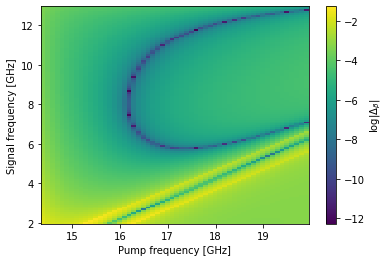

In [3]:
# signals below and pumps above the stopband at ~13.3-14.3 GHz
pm = a.phase_matching(signal_freqs=(2, 13, 0.02), pump_freqs=(14.4, 20, 0.02))
optimal_pump = pm.optimal_pump_freq
print(f"Optimal pump: {optimal_pump:.2f} GHz")
ax = pm.plot(thin=5)

## Gain and bandwidth

The CMEs are solved by Numba-compiled routines: the first call to `gain` compiles them (or loads them from the disk cache), and later calls are fast. `gain` returns a `GainResult` with the gain in `r.gain_db` and the signals in `r.signal_freqs`. By default it solves the `simple` model (the textbook CMEs of a homogeneous line, forward waves only) for pump, signal and idler (`modes="basic_3wm"`); notebook 04 introduces larger mode sets and the `bloch` model, which includes reflections and the exact couplings of the loaded line.

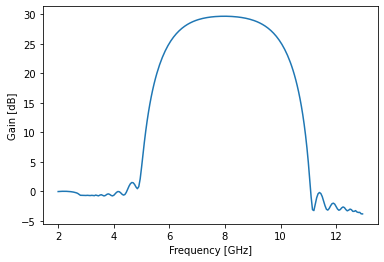

In [4]:
s_arange = np.arange(2, 13, 0.05)
r = a.gain(signal_freqs=s_arange, pump=optimal_pump)
r.plot()
plt.show()

`r.bandwidth()` finds every region where the gain is within a threshold of its maximum (3 dB by default), so the band can be made of disjoint regions when the profile has lobes, as with pump depletion or a pump detuned from phase matching. Here we detune the pump by +0.6 GHz and raise the signal current: the profile splits into two lobes whose dip falls below the threshold, giving two separate bands. Dashed lines mark the band edges and the threshold, the dotted line the mean gain in the band.

Total bandwidth: 4.20 GHz, mean gain in band: 27.4 dB


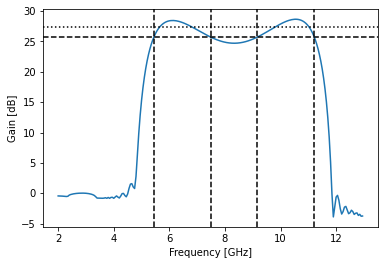

In [5]:
r_det = a.gain(signal_freqs=s_arange, Is0=1e-6, pump=optimal_pump + 0.6)
ax = r_det.plot()
bw = r_det.bandwidth()
for edg in bw["bandwidth_edges"]:
    ax.axvline(edg, color="black", ls="--")
ax.axhline(bw["reduced_gain"], c="black", ls="--")
ax.axhline(bw["mean_gain"], c="black", ls=":")
print(
    f"Total bandwidth: {bw['total_bw']:.2f} GHz, mean gain in band: {bw['mean_gain']:.1f} dB"
)
plt.show()

`r.save("gain.h5")` saves any result to HDF5, and `GainResult.load("gain.h5")` reads it back (`from twpasolver import GainResult`).

## Parameter sweeps

`gain()` returns a self-contained `GainResult`, so a sweep over any input is a loop that collects the results.

### Gain versus pump frequency

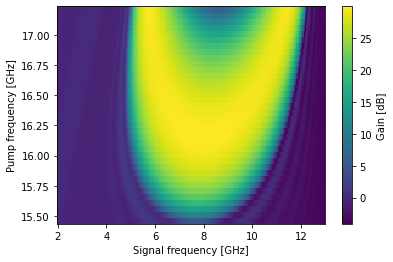

In [6]:
pumps = np.arange(optimal_pump - 0.6, optimal_pump + 1.2, 0.05)
pump_sweep = [a.gain(signal_freqs=s_arange, pump=fp) for fp in pumps]

plt.pcolor(s_arange, pumps, np.array([res.gain_db for res in pump_sweep]))
plt.xlabel("Signal frequency [GHz]")
plt.ylabel("Pump frequency [GHz]")
c = plt.colorbar()
c.set_label("Gain [dB]")
plt.show()

### Compression point

The pump is a dynamical mode of the CMEs, so pump depletion is included and the 1 dB compression point can be simulated. We sweep the signal power, convert it to a current with `dBm_to_I`, and average the gain over the 3 dB band of the phase-matched profile above. The pump power is set the same way, `a.gain(..., Ip0=dBm_to_I(P_dBm, Z0=a.twpa.Z0_ref))`; without `Ip0` the model's `twpa.Ip0` is used. `thin` sets the approximate spacing, in unit cells, of the positions where the currents are stored (`N_tot // thin` points); a large value keeps the results small.

In [7]:
signals_db = np.arange(-90, -50, 1)
signals = dBm_to_I(signals_db)
bw_freqs = r.bandwidth()["bw_freqs"]
compression = [
    a.gain(signal_freqs=bw_freqs, pump=optimal_pump, Is0=Is, thin=1000)
    for Is in signals
]

1 dB compression point: -74.6 dBm


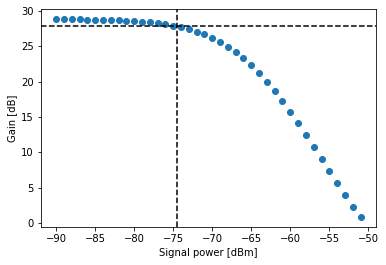

In [8]:
mean_gains = np.array([np.mean(res.gain_db) for res in compression])
reduced_1db = mean_gains[0] - 1
cp_1db = np.interp(reduced_1db, mean_gains[::-1], signals_db[::-1])
print(f"1 dB compression point: {cp_1db:.1f} dBm")
plt.scatter(signals_db, mean_gains)
plt.xlabel("Signal power [dBm]")
plt.ylabel("Gain [dB]")
plt.axhline(reduced_1db, c="black", ls="--")
plt.axvline(cp_1db, c="black", ls="--")
plt.show()